# Stage 5: LSTM

Results of `python -m src.train_lstm` (15-min and 1-h horizons; the day-ahead LSTM is a stretch goal
and was cut, see the `PLAN.md` Change log).

**Input:** the last rows of the same feature table the GBMs use (16 rows = 4 h for 15 min, 24 rows = 1 day
for 1 h), as a sequence. Every value in the window is known when the forecast is issued.

**Protocol:** the same as for the GBMs. Two hidden sizes are tried on train with early stopping on
validation; the better one is refit on train + validation for the same number of epochs; the test year
is scored once.

In [1]:
import pandas as pd
from IPython.display import Image

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
TABLES = "../results/tables/"
FIGURES = "../results/figures/"

## 1. Training curves

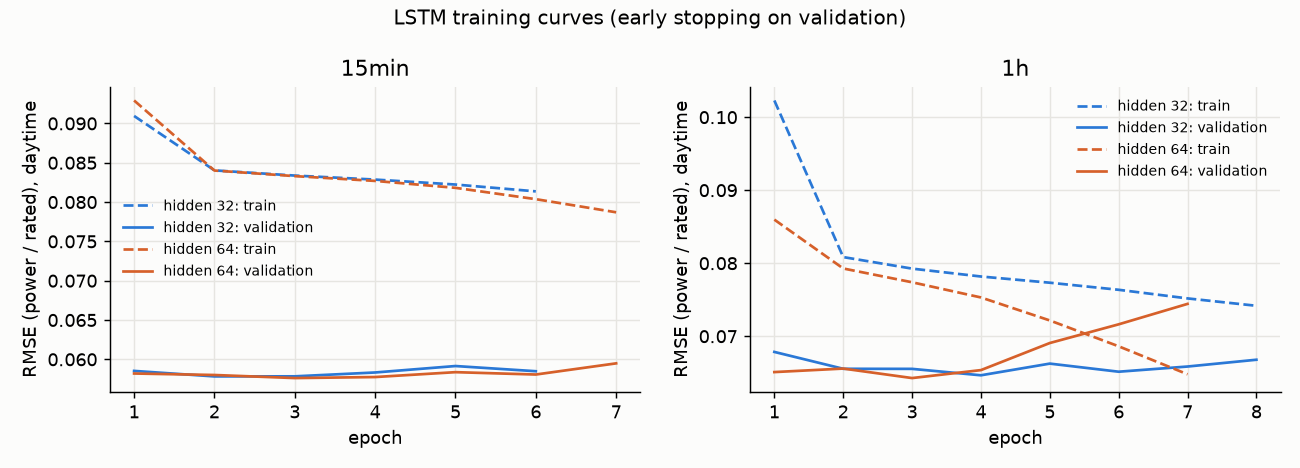

In [2]:
Image(FIGURES + "05_lstm_curves.png")

In [3]:
training = pd.read_csv(TABLES + "05_lstm_training.csv")
search = training[training["run"].str.startswith("train")]
search.groupby(["horizon", "hidden"])["val_rmse"].agg(["min", "count"]).round(5)

min  count
horizon hidden                
15min   32      0.05783      6
        64      0.05762      7
1h      32      0.06465      8
        64      0.06427      7

## 2. LSTM next to every other model (test, daytime)

In [4]:
names = ["03_baselines.csv", "04_gbm_results.csv", "05_lstm_results.csv"]
results = pd.concat([pd.read_csv(TABLES + n) for n in names])
test = results[(results["split"] == "test") & (results["hours"] == "daytime")]
test = test[test["horizon"] != "dayahead"]

In [5]:
columns = ["horizon", "model", "nmae_pct", "nmae_pct_low", "nmae_pct_high", "skill", "skill_low", "skill_high"]
test[columns].sort_values(["horizon", "nmae_pct"]).round(3)

,horizon,model,nmae_pct,nmae_pct_low,nmae_pct_high,skill,skill_low,skill_high
7,15min,xgb,4.609,4.338,4.881,0.112,0.099,0.124
3,15min,lgbm,4.646,4.375,4.922,0.109,0.097,0.120
10,15min,smart_persistence,4.692,4.386,5.002,0.031,0.027,0.035
3,15min,lstm,4.857,4.588,5.118,0.108,0.096,0.119
11,15min,ridge,4.975,4.726,5.229,0.090,0.082,0.097
9,15min,last_value,5.323,5.005,5.623,0.000,0.000,0.000
15,1h,xgb,4.949,4.718,5.203,0.346,0.321,0.369
11,1h,lgbm,4.953,4.717,5.199,0.348,0.324,0.370
7,1h,lstm,5.240,4.989,5.480,0.332,0.309,0.354
22,1h,smart_persistence,5.672,5.417,5.937,0.277,0.257,0.297


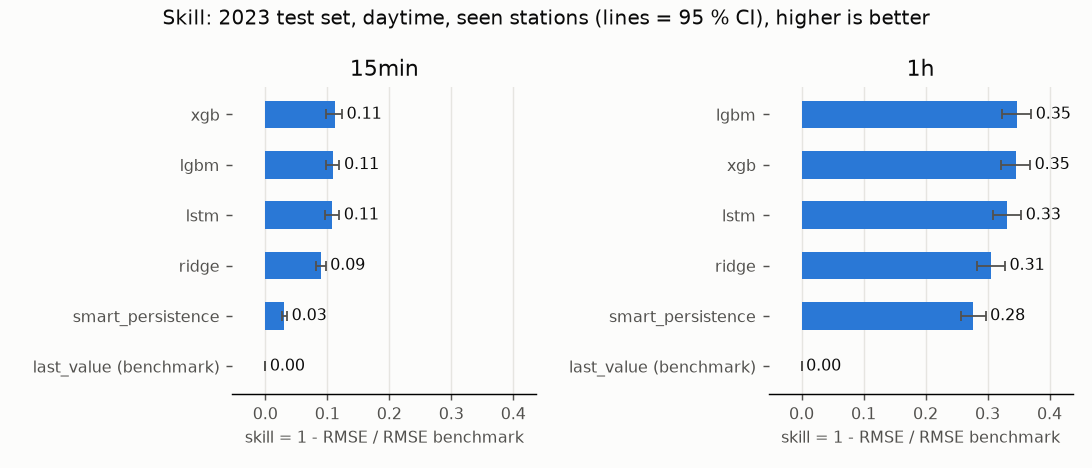

In [6]:
Image(FIGURES + "05_models_skill.png")

## 3. Is the deep model worth its cost?
Training time of the final fit (seconds, this laptop CPU). The latency and size comparison is in Stage 6.

In [7]:
lstm = pd.read_csv(TABLES + "05_lstm_results.csv")
gbm = pd.read_csv(TABLES + "04_gbm_results.csv")
cost = pd.concat([lstm, gbm])
cost = cost[(cost["split"] == "test") & (cost["hours"] == "daytime") & (cost["horizon"] != "dayahead")]
cost[["horizon", "model", "fit_seconds", "nmae_pct", "skill"]].sort_values(["horizon", "nmae_pct"]).round(3)

,horizon,model,fit_seconds,nmae_pct,skill
7,15min,xgb,60.7,4.609,0.112
3,15min,lgbm,36.8,4.646,0.109
3,15min,lstm,421.4,4.857,0.108
15,1h,xgb,21.0,4.949,0.346
11,1h,lgbm,26.7,4.953,0.348
7,1h,lstm,190.0,5.240,0.332
